In [828]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [829]:
import random

# Setting Random Seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [830]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [831]:
dataset_path = "/content/drive/MyDrive/food_dataset"
train = pd.read_csv(dataset_path + "/train_prepared.csv")

test = pd.read_csv(dataset_path + "/test_prepared.csv")


In [832]:
print(train.shape)
print(test.shape)
print(train.columns.tolist())
print(test.columns.tolist())

(456548, 18)
(32573, 17)
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders', 'category', 'cuisine', 'city_code', 'region_code', 'center_type', 'op_area', 'discount_amount', 'discount_percentage', 'promotion_active']
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'category', 'cuisine', 'city_code', 'region_code', 'center_type', 'op_area', 'discount_amount', 'discount_percentage', 'promotion_active']


In [833]:
print(train.dtypes)

id                         int64
week                       int64
center_id                  int64
meal_id                    int64
checkout_price           float64
base_price               float64
emailer_for_promotion      int64
homepage_featured          int64
num_orders                 int64
category                  object
cuisine                   object
city_code                  int64
region_code                int64
center_type               object
op_area                  float64
discount_amount          float64
discount_percentage      float64
promotion_active           int64
dtype: object


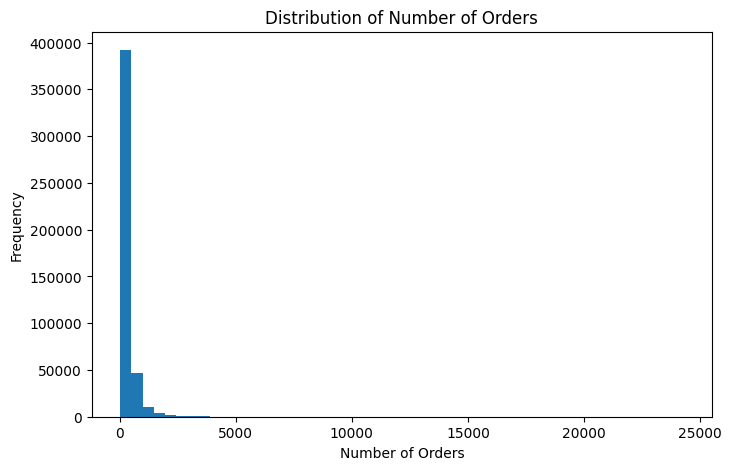

In [834]:
plt.figure(figsize=(8, 5))
plt.hist(train['num_orders'], bins=50)
plt.xlabel("Number of Orders")
plt.ylabel("Frequency")
plt.title("Distribution of Number of Orders")
plt.show()

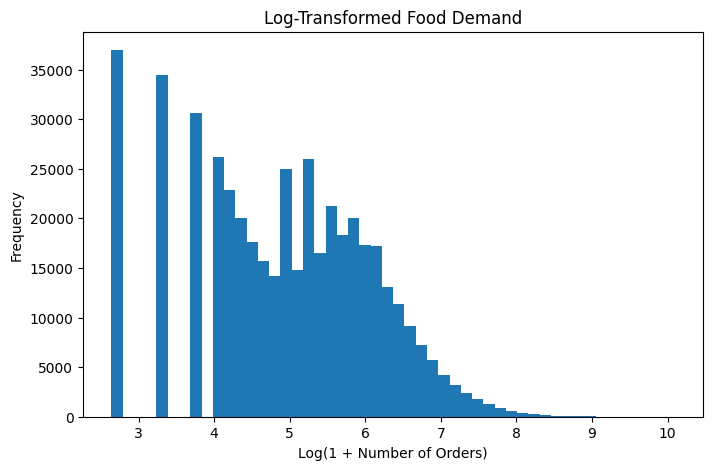

In [835]:
plt.figure(figsize=(8, 5))

plt.hist(np.log1p(train['num_orders']), bins=50)

plt.xlabel("Log(1 + Number of Orders)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Food Demand")

plt.show()

In [836]:
# Input features
X = train.drop(columns=["id", "num_orders"])

# Target variable (log transformation)
y = np.log1p(train["num_orders"])

# Test features
X_test = test.drop(columns=["id"])

In [837]:
# Sorted unique weeks
weeks = sorted(train["week"].unique())

# Calculating split point
split_index = int(len(weeks) * 0.8)

# Validation starting week
split_week = weeks[split_index]

print("Validation starts from week:", split_week)

Validation starts from week: 117


In [838]:
# Training data: earlier weeks
train_data = train[train["week"] < split_week]

# Validation data: later weeks
val_data = train[train["week"] >= split_week]

In [839]:
# Training Features and Target
X_train = train_data.drop(columns=["id", "num_orders"])
y_train = np.log1p(train_data["num_orders"])

# Validation Features and Target
X_val = val_data.drop(columns=["id", "num_orders"])
y_val = np.log1p(val_data["num_orders"])

In [840]:
print("Split week:", split_week)

print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)

print("Training weeks:",
      train_data["week"].min(), "-", train_data["week"].max())

print("Validation weeks:",
      val_data["week"].min(), "-", val_data["week"].max())

Split week: 117
Training shape: (361348, 18)
Validation shape: (95200, 18)
Training weeks: 1 - 116
Validation weeks: 117 - 145


In [841]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)

X_train: (361348, 16)
y_train: (361348,)
X_val: (95200, 16)
y_val: (95200,)
X_test: (32573, 16)


In [842]:
# Identifying Categorical Columns
categorical_cols = ["category", "cuisine", "center_type", "center_id", "meal_id", "city_code", "region_code"]

# Identifying Numerical Columns
numerical_cols = ["week", "checkout_price", "base_price", "op_area", "discount_amount", "discount_percentage"]

# Identifying Binary Columns
binary_cols = ["emailer_for_promotion", "homepage_featured", "promotion_active"]



In [843]:
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Unique count:", X_train[col].nunique())
    print("Unique values:", X_train[col].unique())


Column: category
Unique count: 14
Unique values: ['Beverages' 'Rice Bowl' 'Starters' 'Pasta' 'Sandwich' 'Biryani' 'Extras'
 'Pizza' 'Seafood' 'Other Snacks' 'Desert' 'Soup' 'Salad' 'Fish']

Column: cuisine
Unique count: 4
Unique values: ['Thai' 'Indian' 'Italian' 'Continental']

Column: center_type
Unique count: 3
Unique values: ['TYPE_C' 'TYPE_B' 'TYPE_A']

Column: center_id
Unique count: 77
Unique values: [ 55  24  11  83  32  13 109  52  93 186 146  57 149  89 124 152  97  74
 108  99  66  94  91  20  34 137  92 126  36 162  75 177  27 157 106  64
 129  14  17 153 139 161  81  26  73  50 104  42 113 145  53  72  67 174
  29  77  41  30  76  59  88 143  58  10 101  80  43  65  39 102 110 132
  23  86  68  51  61]

Column: meal_id
Unique count: 51
Unique values: [1885 1993 2539 2139 2631 1248 1778 1062 2707 1207 1230 2322 2290 1727
 1109 2640 2306 2126 2826 1754 1971 1902 1311 1803 1558 2581 1962 1445
 2444 2867 1525 2704 2304 2577 1878 1216 1247 1770 1198 1438 2494 1847
 2760 2492 1

In [844]:
# Creating Preprocessing Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numerical_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

In [845]:
# Fit Only On Training Data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform Validation And Test Data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [846]:
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Data type:", X_train_processed.dtype)

Training shape: (361348, 217)
Validation shape: (95200, 217)
Testing shape: (32573, 217)
Data type: float64


In [847]:
# Convert to dense arrays only if they are sparse
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_val_processed, "toarray"):
    X_val_processed = X_val_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Convert all arrays to float32
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

In [848]:
# Converting Features to Tensors

X_train_tensor = torch.from_numpy(X_train_processed)
X_val_tensor = torch.from_numpy(X_val_processed)
X_test_tensor = torch.from_numpy(X_test_processed)

In [849]:
# Converting Target Variables To Tensors

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)

print("X_test:", X_test_tensor.shape)

X_train: torch.Size([361348, 217])
y_train: torch.Size([361348, 1])
X_val: torch.Size([95200, 217])
y_val: torch.Size([95200, 1])
X_test: torch.Size([32573, 217])


In [850]:
# Creating Tensor Dataset

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor)

In [851]:
# Setting Seed For DataLoader
g = torch.Generator()
g.manual_seed(42)

# Creating DataLoader

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

In [852]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches: ", len(test_loader))

Training batches: 1412
Validation batches: 372
Test batches:  128


In [853]:
for X_batch, y_batch in train_loader:
    print("Input batch shape:", X_batch.shape)
    print("Target batch shape:", y_batch.shape)
    break

Input batch shape: torch.Size([256, 217])
Target batch shape: torch.Size([256, 1])


In [854]:
# Building The ANN Model

class ANNRegressor(nn.Module):
  def __init__(self):
    super(ANNRegressor, self).__init__()

    self.model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),

        nn.Linear(128, 64),
        nn.ReLU(),

        nn.Linear(64, 1)
    )

  def forward(self, x):
    return self.model(x)


In [855]:
# Initializing The Model

model = ANNRegressor()
# print(model)

In [856]:
# Defining Loss Function And Optimizer

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [857]:
print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: L1Loss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [858]:
# Training The Model

# epochs = 30
# for epoch in range(epochs):
#   model.train()
#   running_loss = 0.0
#   for xb, yb in train_loader:
#     optimizer.zero_grad()
#     outputs = model(xb)
#     loss = criterion(outputs, yb)
#     loss.backward()
#     optimizer.step()

#     running_loss += loss.item()

#   train_loss = running_loss / len(train_loader)
#   print(f"Epoch = {epoch+1}/{epochs} And Loss = {train_loss}")

import copy
epochs = 100
patience = 10
best_val_loss = float("inf")
best_model = copy.deepcopy(model.state_dict())
counter = 0

train_losses = []
val_losses = []

for epoch in range(epochs):
  model.train()

  running_loss = 0.0

  for xb, yb in train_loader:
    optimizer.zero_grad()
    outputs = model(xb)
    loss = criterion(outputs, yb)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

  train_loss = running_loss / len(train_loader)

  # Validation

  model.eval()
  running_loss = 0.0
  with torch.no_grad():
    for xb, yb in val_loader:
      outputs = model(xb)
      loss = criterion(outputs, yb)
      running_loss += loss.item()
    val_loss = running_loss / len(val_loader)

  train_losses.append(train_loss)
  val_losses.append(val_loss)


  # Save The Best Model

  if val_loss < best_val_loss - 0.0001:
    best_val_loss = val_loss
    best_model = copy.deepcopy(model.state_dict())
    counter = 0
  else:
    counter += 1


  print(f"Epoch = {epoch+1}/{epochs}, Train Loss = {train_loss}, Validation Loss = {val_loss}")

  # Early Stopping

  if counter >= patience:
    print("Early stopping triggered!")
    break

# Load Best Model
model.load_state_dict(best_model)

print("\nTraining Completed!")
print(f"Best Validation Loss: {best_val_loss}")

Epoch = 1/100, Train Loss = 0.5345643140987701, Validation Loss = 0.41610237002693196
Epoch = 2/100, Train Loss = 0.39360968812920216, Validation Loss = 0.4172473740513607
Epoch = 3/100, Train Loss = 0.3868313266687285, Validation Loss = 0.41490835944811505
Epoch = 4/100, Train Loss = 0.3832473577377479, Validation Loss = 0.4096283593805887
Epoch = 5/100, Train Loss = 0.38061185362656463, Validation Loss = 0.40590756210268186
Epoch = 6/100, Train Loss = 0.37820219679105044, Validation Loss = 0.40576358419913117
Epoch = 7/100, Train Loss = 0.37611627663161196, Validation Loss = 0.4286275577320847
Epoch = 8/100, Train Loss = 0.3751134524179923, Validation Loss = 0.4176036921399896
Epoch = 9/100, Train Loss = 0.37432483273423767, Validation Loss = 0.4238366080067491
Epoch = 10/100, Train Loss = 0.3721798511892135, Validation Loss = 0.4126010604443089
Epoch = 11/100, Train Loss = 0.3709870946221581, Validation Loss = 0.4096075714595856
Epoch = 12/100, Train Loss = 0.3703053988537437, Valid

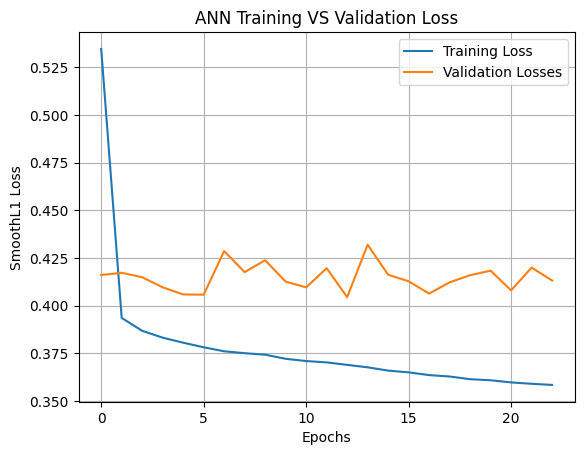

In [859]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Losses")
plt.title("ANN Training VS Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("SmoothL1 Loss")
plt.legend()
plt.grid()
plt.show()

In [860]:
# Making Predictions

model.eval()

y_pred = []

with torch.no_grad():
  for xb in test_loader:
    outputs = model(xb[0])

    y_pred.extend(outputs.cpu().numpy().reshape(-1))

print("Predictions Completed!")
print("Total Predictions = ", len(y_pred))

Predictions Completed!
Total Predictions =  32573


In [861]:
# Inverse Transformation
y_pred_actual = np.expm1(np.array(y_pred))

# Removing Negative Predictions
y_pred_actual = np.maximum(y_pred_actual, 0)

In [862]:
# Validation Predictions And Metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()

y_val_pred = []
y_val_actual = []

with torch.no_grad():
  for xb, yb in val_loader:
    outputs = model(xb)

    y_val_pred.extend(outputs.cpu().numpy().reshape(-1))
    y_val_actual.extend(yb.cpu().numpy().reshape(-1))

# Inverse Transformation
y_val_pred = np.expm1(np.array(y_val_pred))
y_val_actual = np.expm1(np.array(y_val_actual))

y_val_pred = np.maximum(y_val_pred, 0)


# Evaluation Metrics

mae = mean_absolute_error(y_val_actual, y_val_pred)
mse = mean_squared_error(y_val_actual, y_val_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val_actual, y_val_pred)

print("Evaluation Metrices: ")
print("MAE: ", mae)
print("MSE: ", mse)
print("RMSE: ", rmse)
print("R2 Score: ", r2)

Evaluation Metrices: 
MAE:  78.86698150634766
MSE:  26727.4921875
RMSE:  163.48544946722322
R2 Score:  0.7996119260787964


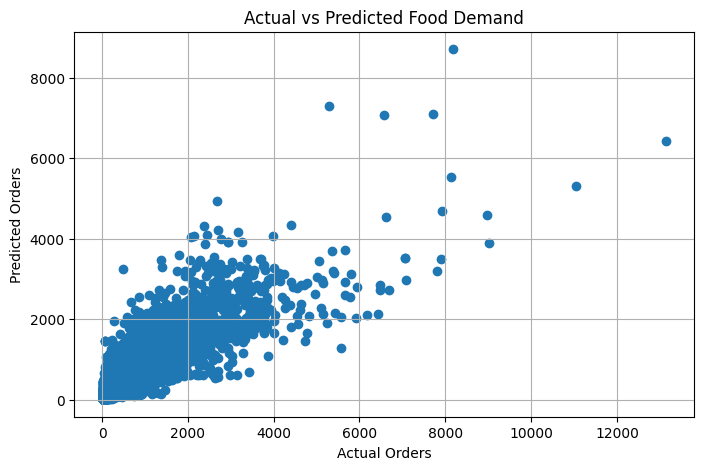

In [863]:
plt.figure(figsize=(8, 5))

plt.scatter(y_val_actual, y_val_pred)

plt.xlabel("Actual Orders")
plt.ylabel("Predicted Orders")
plt.title("Actual vs Predicted Food Demand")

plt.grid()
plt.show()

In [864]:
comparison = pd.DataFrame({
    "Actual Orders": y_val_actual,
    "Predicted Orders": y_val_pred
                          })
comparison["Error"] = (
    comparison["Actual Orders"] -
    comparison["Predicted Orders"]
)

comparison["Absolute Error"] = abs(comparison["Error"])

print(comparison.head(10))
print("\nAverage Absolute Error:", comparison["Absolute Error"].mean())

   Actual Orders  Predicted Orders       Error  Absolute Error
0     161.999969        213.192093  -51.192123       51.192123
1     135.000000        189.519653  -54.519653       54.519653
2     163.000000        138.503448   24.496552       24.496552
3      41.000004         18.406391   22.593613       22.593613
4      81.000000         43.219948   37.780052       37.780052
5      27.999998         35.593056   -7.593058        7.593058
6     297.000000        179.860291  117.139709      117.139709
7     215.999954        201.209778   14.790176       14.790176
8     514.000000        246.365051  267.634949      267.634949
9     217.000046         75.537949  141.462097      141.462097

Average Absolute Error: 78.86698


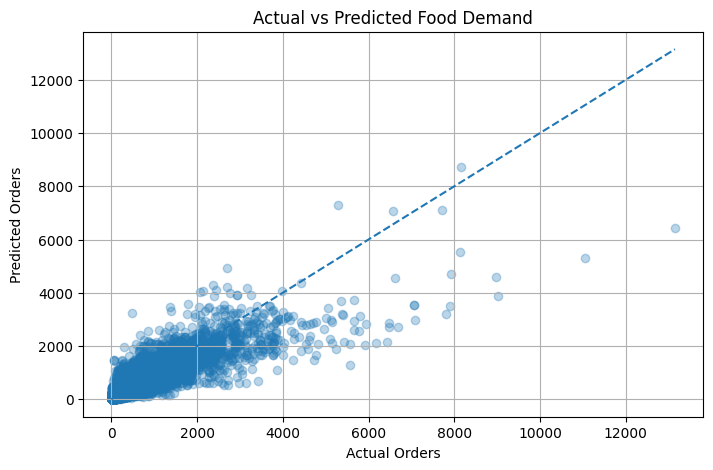

In [865]:
plt.figure(figsize=(8, 5))

plt.scatter(
    comparison["Actual Orders"],
    comparison["Predicted Orders"],
    alpha=0.3
)

max_value = comparison["Actual Orders"].max()

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Orders")
plt.ylabel("Predicted Orders")
plt.title("Actual vs Predicted Food Demand")

plt.grid()
plt.show()

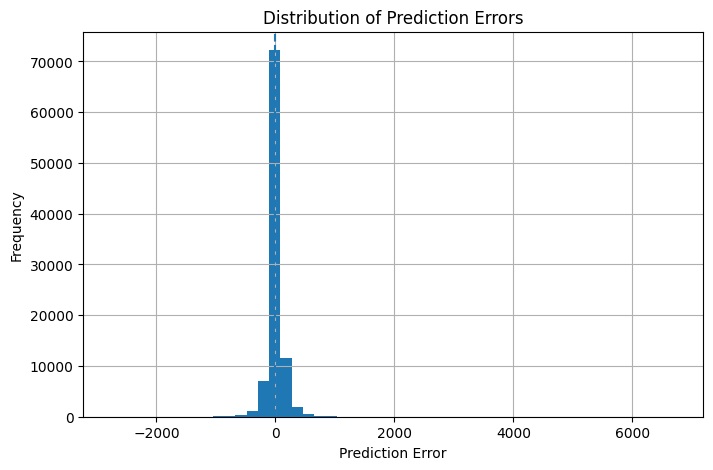

In [866]:
plt.figure(figsize=(8, 5))

plt.hist(comparison["Error"], bins=50)

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.grid()
plt.show()

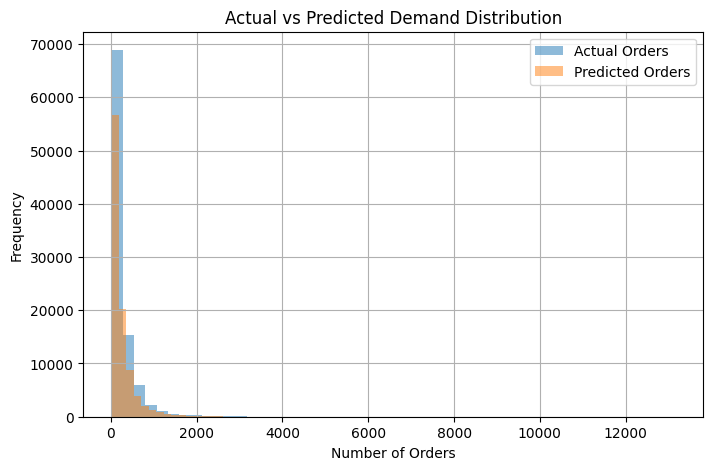

In [867]:
plt.figure(figsize=(8, 5))

plt.hist(
    comparison["Actual Orders"],
    bins=50,
    alpha=0.5,
    label="Actual Orders"
)

plt.hist(
    comparison["Predicted Orders"],
    bins=50,
    alpha=0.5,
    label="Predicted Orders"
)

plt.xlabel("Number of Orders")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Demand Distribution")

plt.legend()
plt.grid()
plt.show()

In [868]:
comparison["Category"] = val_data["category"].values
category_performance = comparison.groupby("Category").agg(
    MAE=("Absolute Error", "mean"),
    Average_Actual=("Actual Orders", "mean"),
    Average_Predicted=("Predicted Orders", "mean")
).reset_index()

print(category_performance)

        Category         MAE  Average_Actual  Average_Predicted
0      Beverages   81.661957      294.966187         276.470093
1        Biryani   13.508955       32.332867          29.515684
2         Desert   30.967352       76.999352          83.265793
3         Extras   77.193489      268.242126         261.624146
4           Fish   51.761555      102.278229         121.883171
5   Other Snacks   45.212269      153.283737         141.158569
6          Pasta   28.529427       57.116344          65.982559
7          Pizza   69.404976      226.826569         227.662384
8      Rice Bowl  178.907837      617.722656         560.845459
9          Salad  130.833374      332.511566         383.257385
10      Sandwich  177.336212      538.381470         480.990875
11       Seafood   36.242085       85.280449          71.659126
12          Soup   40.866375      109.884880          91.385147
13      Starters   44.906788      123.060966         135.973511


In [870]:
category_performance["MAE_Percentage"] = (
    category_performance["MAE"] /
    category_performance["Average_Actual"]
) * 100

category_performance = category_performance.sort_values(
    by="MAE_Percentage"
)

print(category_performance)

        Category         MAE  Average_Actual  Average_Predicted  \
0      Beverages   81.661957      294.966187         276.470093   
3         Extras   77.193489      268.242126         261.624146   
8      Rice Bowl  178.907837      617.722656         560.845459   
5   Other Snacks   45.212269      153.283737         141.158569   
7          Pizza   69.404976      226.826569         227.662384   
10      Sandwich  177.336212      538.381470         480.990875   
13      Starters   44.906788      123.060966         135.973511   
12          Soup   40.866375      109.884880          91.385147   
9          Salad  130.833374      332.511566         383.257385   
2         Desert   30.967352       76.999352          83.265793   
1        Biryani   13.508955       32.332867          29.515684   
11       Seafood   36.242085       85.280449          71.659126   
6          Pasta   28.529427       57.116344          65.982559   
4           Fish   51.761555      102.278229         121.88317

In [871]:
import joblib

torch.save(model.state_dict(), "ann_regressor.pth")
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']

In [872]:
import os

model_path = "/content/drive/MyDrive/SmartFood_Rescue/models"

os.makedirs(model_path, exist_ok=True)

torch.save(
    model.state_dict(),
    model_path + "/ann_regressor.pth"
)

joblib.dump(
    preprocessor,
    model_path + "/preprocessor.pkl"
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
